# ShopSphere Repurchase Prediction: LightGBM Baseline (v2, fixed and team-ready)
**Course:** IT2226 AI Innovation and Deep Learning Project  
**Target:** `target = 1` if the customer buys between 1 and 30 Oct 2024  
**Role:** the classical (non-deep-learning) baseline that every deep model is compared against.

## What changed from the previous version, and why
| # | Change | Why it matters |
|---|---|---|
| 1 | `late_deliveries_count` now matches `'Delivered Late'` (was `'Late'`, which never occurs) | the feature was always 0. A check now asserts it matches the deliveries table |
| 2 | Early stopping watches **AUC only** (was AUC **and** logloss) | with `scale_pos_weight`, logloss worsens almost immediately, so training stopped after ~18 trees (undertrained). Section 8 tests this |
| 3 | Class weighting is a switch, **off by default** | plain loss gives calibrated probabilities (needed for budgeting) and matches the FT-Transformer's plain BCE |
| 4 | `bagging_freq=1` added | `subsample=0.8` was silently ignored without it |
| 5 | Loads the team's shared `folds.csv` (creates it if absent) | identical splits across all models, so comparisons are fair |
| 6 | Exports `oof_lightgbm.csv`, probability and label submissions, `features_v1.parquet`, per-fold models | the OOF file feeds the fold-by-fold comparison in the FT-Transformer notebook |
| 7 | Evaluation code identical to the FT-Transformer notebook (precision@k, Brier, calibration, F1 sweep) | same metrics, same definitions |
| 8 | Out-of-fold SHAP importance (built in, no extra library) and per-customer "why" | serves W2 (explain the prediction) and is ready to compare with the deep model |
| 9 | `test_customer()` uses the fold models, shows reasons, respects opt-out and open complaints | the old one used only the last fold's model and ignored consent |

The SQL feature query is unchanged apart from change 1, so your code walkthrough of it stays the same.

## 1. Setup and CONFIG

In [1]:
%pip install -q lightgbm scikit-learn matplotlib

import os, time, json, sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss,
                             f1_score, roc_curve, precision_recall_curve)
from sklearn.calibration import calibration_curve
import lightgbm as lgb

print("LightGBM", lgb.__version__)

LightGBM 4.6.0


In [2]:
# ----------------------------------------------------------------------------------------------
# CONFIG: every setting in one place. An experiment = one config + one set of results.
# ----------------------------------------------------------------------------------------------
CONFIG = {
    # ---------- files ----------
    "db_path": "shopsphere.db",
    "folds_path": "folds.csv",                  # shared by the whole team: customer_id, fold (0..4)
    "features_path": "features_v1.parquet",     # shared feature table used by the deep-learning notebooks
    "ft_oof_path": "oof_ft_transformer.csv",    # optional: enables the comparison in section 9

    # ---------- validation ----------
    "n_splits": 5,
    "fold_seed": 42,        # only used to CREATE folds.csv if it does not exist yet
    "seed": 42,             # model randomness

    # ---------- model (minimal tuning: fixed values, no search) ----------
    "use_class_weight": False,      # False = plain loss, calibrated probabilities (matches the FT-Transformer)
    "learning_rate": 0.03,
    "num_leaves": 31,
    "min_child_samples": 30,
    "bagging_fraction": 0.8,
    "feature_fraction": 0.8,
    "max_rounds": 3000,
    "early_stopping_rounds": 100,

    # ---------- extras ----------
    "run_variants": True,            # section 8: documents WHY the baseline changed (adds ~2 CV runs)
    "overwrite_features": False,     # never overwrite the team's shared features file by accident
    "shap_rows_per_fold": 3000,      # validation rows explained per fold (out-of-fold SHAP)
    "run_name": "lightgbm_v2_fixed",

    # ---------- demo only: placeholder segment cut-offs on the predicted probability ----------
    # (the real agent should decide who to contact from budget, offer cost and policy, not from these)
    "segment_cuts": {"organic": 0.50, "at_risk": 0.10},
    "demo_customer_id": 10126,

    # ---------- the previous (flawed) baseline, kept for the report ----------
    "old_baseline": {"roc_auc": 0.87025, "pr_auc": 0.54194},
}
os.makedirs("artifacts", exist_ok=True)
print(json.dumps({k: v for k, v in CONFIG.items() if k != "segment_cuts"}, indent=1))

{
 "db_path": "shopsphere.db",
 "folds_path": "folds.csv",
 "features_path": "features_v1.parquet",
 "ft_oof_path": "oof_ft_transformer.csv",
 "n_splits": 5,
 "fold_seed": 42,
 "seed": 42,
 "use_class_weight": false,
 "learning_rate": 0.03,
 "num_leaves": 31,
 "min_child_samples": 30,
 "bagging_fraction": 0.8,
 "feature_fraction": 0.8,
 "max_rounds": 3000,
 "early_stopping_rounds": 100,
 "run_variants": true,
 "overwrite_features": false,
 "shap_rows_per_fold": 3000,
 "run_name": "lightgbm_v2_fixed",
 "demo_customer_id": 10126,
 "old_baseline": {
  "roc_auc": 0.87025,
  "pr_auc": 0.54194
 }
}


## 2. Database and SQL feature extraction
Child tables (transactions, sessions, deliveries, tickets, retention contacts) are aggregated to one row per customer **inside SQLite**, then joined to the customer profile. All history ends at the 2024-09-30 cutoff, so no feature uses October information.

In [3]:
DB_PATH = CONFIG["db_path"]
if not os.path.exists(DB_PATH):
    print(f"{DB_PATH} not found. Choose it in the upload dialog.")
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Put {DB_PATH} next to this notebook.")
assert os.path.exists(DB_PATH), "database still missing"
print(f"Database: {DB_PATH} ({os.path.getsize(DB_PATH) / 1024 / 1024:.1f} MB)")

def q(sql):
    # Run a query on a READ-ONLY connection and return a DataFrame (the data pack must never be altered).
    conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True)
    try:
        return pd.read_sql_query(sql, conn)
    finally:
        conn.close()

Database: shopsphere.db (246.3 MB)


In [4]:
t0 = time.time()

feature_query = '''
WITH cust_rfm AS (
    SELECT
        customer_id,
        COUNT(transaction_id) AS total_orders,
        COALESCE(SUM(order_value), 0.0) AS total_spend_usd,
        COALESCE(AVG(order_value), 0.0) AS avg_order_value,
        COALESCE(MAX(order_value), 0.0) AS max_order_value,
        COALESCE(SUM(items_count), 0) AS total_items_bought,
        COALESCE(SUM(discount_applied), 0) AS discounted_orders_count,
        COALESCE(SUM(high_value_flag), 0) AS high_value_orders_count,
        COALESCE(SUM(CASE WHEN transaction_timestamp >= '2024-09-01' THEN 1 ELSE 0 END), 0) AS orders_last_30d,
        COALESCE(SUM(CASE WHEN transaction_timestamp >= '2024-07-01' THEN 1 ELSE 0 END), 0) AS orders_last_90d,
        ROUND(JULIANDAY('2024-09-30') - JULIANDAY(MAX(transaction_timestamp)), 1) AS recency_days
    FROM transactions
    GROUP BY customer_id
),
cust_sessions AS (
    SELECT
        customer_id,
        COUNT(session_id) AS total_sessions,
        COALESCE(SUM(pages_viewed), 0) AS total_pages_viewed,
        COALESCE(SUM(cart_additions), 0) AS total_cart_additions,
        COALESCE(SUM(bounce_flag), 0) AS total_bounced_sessions,
        COALESCE(AVG(session_duration_capped), 0.0) AS avg_session_duration_s,
        COALESCE(SUM(CASE WHEN session_timestamp >= '2024-09-01' THEN 1 ELSE 0 END), 0) AS sessions_last_30d,
        COALESCE(SUM(CASE WHEN session_timestamp >= '2024-07-01' THEN 1 ELSE 0 END), 0) AS sessions_last_90d,
        ROUND(JULIANDAY('2024-09-30') - JULIANDAY(MAX(session_timestamp)), 1) AS days_since_last_session
    FROM sessions
    GROUP BY customer_id
),
cust_deliveries AS (
    SELECT
        t.customer_id,
        COUNT(d.transaction_id) AS total_deliveries,
        COALESCE(SUM(CASE WHEN d.delivery_status = 'Delivered Late' THEN 1 ELSE 0 END), 0) AS late_deliveries_count,
        COALESCE(SUM(CASE WHEN d.delivery_status = 'Lost' THEN 1 ELSE 0 END), 0) AS lost_packages_count,
        COALESCE(AVG(d.delay_days), 0.0) AS avg_delay_days
    FROM transactions t
    JOIN deliveries d ON t.transaction_id = d.transaction_id
    GROUP BY t.customer_id
),
cust_tickets AS (
    SELECT
        customer_id,
        COUNT(ticket_id) AS total_support_tickets,
        COALESCE(SUM(CASE WHEN status = 'Open' THEN 1 ELSE 0 END), 0) AS open_tickets_count,
        COALESCE(SUM(CASE WHEN status = 'Open' AND priority IN ('High', 'Urgent') THEN 1 ELSE 0 END), 0) AS high_priority_open_tickets,
        AVG(csat_score) AS avg_csat_score
    FROM support_tickets
    GROUP BY customer_id
),
cust_retention AS (
    SELECT
        customer_id,
        COUNT(contact_id) AS retention_contacts_count,
        COALESCE(SUM(redeemed), 0) AS retention_redeemed_count,
        COALESCE(SUM(purchased_within_14d), 0) AS retention_purchased_count
    FROM retention_contact_history
    GROUP BY customer_id
)
SELECT
    c.customer_id,
    c.age,
    c.age_is_missing,
    c.country_code,
    c.customer_tier,
    c.credit_limit,
    c.loyalty_score,
    c.email_open_rate,
    c.email_open_rate_is_missing,
    c.avg_review_score,
    ROUND(JULIANDAY('2024-09-30') - JULIANDAY(c.signup_date), 1) AS account_age_days,
    COALESCE(p.email_opt_in, 0) AS email_opt_in,
    COALESCE(p.sms_opt_in, 0) AS sms_opt_in,
    COALESCE(p.do_not_contact, 0) AS do_not_contact,
    COALESCE(p.preferred_channel, 'unknown') AS preferred_channel,
    COALESCE(rfm.total_orders, 0) AS total_orders,
    COALESCE(rfm.total_spend_usd, 0.0) AS total_spend_usd,
    COALESCE(rfm.avg_order_value, 0.0) AS avg_order_value,
    COALESCE(rfm.max_order_value, 0.0) AS max_order_value,
    COALESCE(rfm.total_items_bought, 0) AS total_items_bought,
    COALESCE(rfm.discounted_orders_count, 0) AS discounted_orders_count,
    COALESCE(rfm.high_value_orders_count, 0) AS high_value_orders_count,
    COALESCE(rfm.orders_last_30d, 0) AS orders_last_30d,
    COALESCE(rfm.orders_last_90d, 0) AS orders_last_90d,
    rfm.recency_days,
    COALESCE(s.total_sessions, 0) AS total_sessions,
    COALESCE(s.total_pages_viewed, 0) AS total_pages_viewed,
    COALESCE(s.total_cart_additions, 0) AS total_cart_additions,
    COALESCE(s.total_bounced_sessions, 0) AS total_bounced_sessions,
    COALESCE(s.avg_session_duration_s, 0.0) AS avg_session_duration_s,
    COALESCE(s.sessions_last_30d, 0) AS sessions_last_30d,
    COALESCE(s.sessions_last_90d, 0) AS sessions_last_90d,
    s.days_since_last_session,
    COALESCE(d.total_deliveries, 0) AS total_deliveries,
    COALESCE(d.late_deliveries_count, 0) AS late_deliveries_count,
    COALESCE(d.lost_packages_count, 0) AS lost_packages_count,
    COALESCE(d.avg_delay_days, 0.0) AS avg_delay_days,
    COALESCE(t.total_support_tickets, 0) AS total_support_tickets,
    COALESCE(t.open_tickets_count, 0) AS open_tickets_count,
    COALESCE(t.high_priority_open_tickets, 0) AS high_priority_open_tickets,
    t.avg_csat_score,
    COALESCE(r.retention_contacts_count, 0) AS retention_contacts_count,
    COALESCE(r.retention_redeemed_count, 0) AS retention_redeemed_count,
    COALESCE(r.retention_purchased_count, 0) AS retention_purchased_count,
    tr.target,
    CASE WHEN te.customer_id IS NOT NULL THEN 1 ELSE 0 END AS is_test
FROM customers c
LEFT JOIN customer_preferences p ON c.customer_id = p.customer_id
LEFT JOIN cust_rfm rfm ON c.customer_id = rfm.customer_id
LEFT JOIN cust_sessions s ON c.customer_id = s.customer_id
LEFT JOIN cust_deliveries d ON c.customer_id = d.customer_id
LEFT JOIN cust_tickets t ON c.customer_id = t.customer_id
LEFT JOIN cust_retention r ON c.customer_id = r.customer_id
LEFT JOIN train tr ON c.customer_id = tr.customer_id
LEFT JOIN test te ON c.customer_id = te.customer_id;
'''

df = q(feature_query)
print(f"Extracted {len(df):,} customer records in {time.time() - t0:.2f} seconds.")

Extracted 80,000 customer records in 11.38 seconds.


## 3. Feature engineering, data checks and shared files

In [5]:
# Derived domain ratios (unchanged)
df["discount_order_ratio"] = np.where(df["total_orders"] > 0, df["discounted_orders_count"] / df["total_orders"], 0.0)
df["bounce_rate"] = np.where(df["total_sessions"] > 0, df["total_bounced_sessions"] / df["total_sessions"], 0.0)
df["cart_abandonment_ratio"] = np.where(
    df["total_cart_additions"] > 0,
    np.clip(1.0 - (df["total_orders"] / df["total_cart_additions"]), 0.0, 1.0),
    0.0,
)
df["is_inactive_90d"] = ((df["orders_last_90d"] == 0) & (df["sessions_last_90d"] == 0)).astype(int)

# LightGBM handles categoricals natively when they have the pandas 'category' dtype
CATEGORICAL_COLS = ["country_code", "customer_tier", "preferred_channel"]
for col in CATEGORICAL_COLS:
    df[col] = df[col].astype("category")

EXCLUDE_COLS = ["customer_id", "target", "is_test"]
FEATURE_COLS = [c for c in df.columns if c not in EXCLUDE_COLS]   # decided BEFORE any fold column is added
print(f"Engineered features: {len(FEATURE_COLS)} (expected 47)")

# ---- check 1: the late-delivery fix worked (feature total must equal the deliveries table) ----
late_in_features = int(df["late_deliveries_count"].sum())
late_in_table = int(q('''SELECT COUNT(*) AS n FROM deliveries d
                         JOIN transactions t ON t.transaction_id = d.transaction_id
                         WHERE d.delivery_status = 'Delivered Late' ''')["n"][0])
print(f"late_deliveries_count: feature total {late_in_features:,} vs deliveries table {late_in_table:,}")
assert late_in_features == late_in_table, "late_deliveries_count does not match the deliveries table"

# ---- check 2: no constant (information-free) feature ----
constant = [c for c in FEATURE_COLS if df[c].nunique(dropna=False) <= 1]
print("Constant features:", constant if constant else "none")
assert not constant, "a feature is constant, check the SQL"

train_df = df[df["is_test"] == 0].reset_index(drop=True)
test_df = df[df["is_test"] == 1].reset_index(drop=True)
print(f"Train customers: {len(train_df):,} | repurchase rate {train_df['target'].mean():.2%} | Test customers: {len(test_df):,}")

Engineered features: 47 (expected 47)
late_deliveries_count: feature total 26,799 vs deliveries table 26,799
Constant features: none
Train customers: 64,000 | repurchase rate 14.57% | Test customers: 16,000


In [6]:
# ---- Is this feature table identical to the team's shared one? ----
# The deep-learning notebooks read features_v1.parquet. If it differs from what this SQL produces,
# the models are NOT being compared on the same inputs.
def compare_to_shared(mine, shared):
    a = mine.sort_values("customer_id").reset_index(drop=True)
    b = shared.sort_values("customer_id").reset_index(drop=True)
    problems = []
    if set(a.columns) != set(b.columns):
        problems.append(f"column sets differ: only here {sorted(set(a.columns) - set(b.columns))}, only shared {sorted(set(b.columns) - set(a.columns))}")
    if len(a) != len(b) or not (a["customer_id"].values == b["customer_id"].values).all():
        problems.append("customer rows differ")
        return problems
    for c in sorted(set(a.columns) & set(b.columns)):
        if a[c].dtype.name == "category" or b[c].dtype.name == "category" or a[c].dtype == object or b[c].dtype == object:
            same = (a[c].astype(str).values == b[c].astype(str).values).all()
        else:
            same = np.allclose(a[c].astype(float), b[c].astype(float), equal_nan=True, rtol=1e-6, atol=1e-6)
        if not same:
            problems.append(f"values differ in '{c}'")
    return problems

fp = CONFIG["features_path"]
if os.path.exists(fp):
    problems = compare_to_shared(df, pd.read_parquet(fp))
    print(f"Comparison with shared {fp}:", "IDENTICAL" if not problems else "")
    for p in problems:
        print("  -", p)
    if problems and not CONFIG["overwrite_features"]:
        print("  Resolve this before comparing models. (Set overwrite_features=True only if THIS table is the correct one.)")
if (not os.path.exists(fp)) or CONFIG["overwrite_features"]:
    df.to_parquet(fp)
    print(f"Wrote {fp} ({len(df):,} rows). Share it with the team.")

Comparison with shared features_v1.parquet: IDENTICAL


In [7]:
# ---- Leakage and data checks kept from the previous version (run once, read the output) ----
print("A. Delivery statuses (the SQL must use one of these exact spellings)")
display(q("SELECT delivery_status, COUNT(*) AS n FROM deliveries GROUP BY 1 ORDER BY 2 DESC"))

print("B. Retention contacts after 16 Sep: do they encode October purchases? (october_only should be 0)")
display(q('''
SELECT COUNT(*) AS contacts,
       SUM(purchased_within_14d) AS flagged_purchase,
       SUM(CASE WHEN purchased_within_14d = 1 AND NOT EXISTS (
               SELECT 1 FROM transactions t
               WHERE t.customer_id = r.customer_id
                 AND t.transaction_timestamp BETWEEN r.contact_date AND '2024-09-30')
           THEN 1 ELSE 0 END) AS october_only,
       SUM(CASE WHEN redemption_date > '2024-09-30' THEN 1 ELSE 0 END) AS redeemed_in_october
FROM retention_contact_history r
WHERE contact_date > '2024-09-16'
'''))

print("C. Deliveries resolved after 30 Sep (should be 0 so no feature uses post-cutoff information)")
display(q('''
SELECT COUNT(*) AS delivered_after_cutoff
FROM deliveries WHERE delivered_date > '2024-09-30'
'''))

print("D. sample_submission placeholder values (does not say whether labels or probabilities are expected)")
display(q("SELECT target, COUNT(*) AS n FROM sample_submission GROUP BY 1 LIMIT 10"))

A. Delivery statuses (the SQL must use one of these exact spellings)


,delivery_status,n
0,Delivered,260124
1,Delivered Late,26799
2,Returned,9400
3,In Transit,3222
4,Lost,1698


B. Retention contacts after 16 Sep: do they encode October purchases? (october_only should be 0)


,contacts,flagged_purchase,october_only,redeemed_in_october
0,1419,91,0,0


C. Deliveries resolved after 30 Sep (should be 0 so no feature uses post-cutoff information)


,delivered_after_cutoff
0,0


D. sample_submission placeholder values (does not say whether labels or probabilities are expected)


,target,n
0,0,16000


## 4. Shared folds
All models must be trained and validated on **identical customers**. We load the team's `folds.csv`; if it does not exist yet, we create it with `StratifiedKFold(5, shuffle=True, random_state=42)` and save it for the others.

In [8]:
FP = CONFIG["folds_path"]
if not os.path.exists(FP):
    print(f"{FP} not found. If a teammate already shared one, choose it in the dialog (cancel to create it).")
    try:
        from google.colab import files
        files.upload()
    except Exception:
        pass

if os.path.exists(FP):
    folds = pd.read_csv(FP)
    print(f"Loaded shared folds: {FP}")
else:
    skf0 = StratifiedKFold(n_splits=CONFIG["n_splits"], shuffle=True, random_state=CONFIG["fold_seed"])
    fold_id = np.full(len(train_df), -1)
    for k, (_, va_idx) in enumerate(skf0.split(train_df, train_df["target"].astype(int))):
        fold_id[va_idx] = k
    folds = pd.DataFrame({"customer_id": train_df["customer_id"].values, "fold": fold_id})
    folds.to_csv(FP, index=False)
    print(f"Created {FP} with StratifiedKFold(seed {CONFIG['fold_seed']}). Share it with the team.")

train_df = train_df.merge(folds, on="customer_id", how="left")    # left merge keeps train_df's row order
assert train_df["fold"].notna().all(), "some training customers are missing from folds.csv"
assert len(folds) == len(train_df) and set(train_df["fold"].unique()) == set(range(CONFIG["n_splits"]))
train_df["fold"] = train_df["fold"].astype(int)

# Is the shared file the same as a fresh seed-42 split? (documents reproducibility for the report)
ref = np.full(len(train_df), -1)
for k, (_, va_idx) in enumerate(StratifiedKFold(CONFIG["n_splits"], shuffle=True, random_state=CONFIG["fold_seed"]).split(train_df, train_df["target"].astype(int))):
    ref[va_idx] = k
print("Identical to a fresh StratifiedKFold(5, shuffle, seed 42) on this row order:", bool((ref == train_df["fold"].values).all()))
print("\nRows and positive rate per fold:")
print(train_df.groupby("fold")["target"].agg(["size", "mean"]).round(4).T)

X = train_df[FEATURE_COLS]
y = train_df["target"].astype(int)
X_test = test_df[FEATURE_COLS]

Loaded shared folds: folds.csv
Identical to a fresh StratifiedKFold(5, shuffle, seed 42) on this row order: True

Rows and positive rate per fold:
fold           0           1           2           3           4
size  12800.0000  12800.0000  12800.0000  12800.0000  12800.0000
mean      0.1457      0.1457      0.1457      0.1457      0.1458


## 5. Cross-validation
`run_cv` trains one model per fold on the other four folds and predicts the held-out fold (the **out-of-fold, OOF** predictions). Test predictions are the average of the five fold models. Early stopping uses **validation AUC only** (the same rule as the deep models, where it is also scored on the validation fold, so both are slightly optimistic by the same mechanism).

In [9]:
def make_params(use_class_weight, metric="auc"):
    p = dict(
        objective="binary", metric=metric, boosting_type="gbdt",
        learning_rate=CONFIG["learning_rate"], num_leaves=CONFIG["num_leaves"], max_depth=-1,
        min_child_samples=CONFIG["min_child_samples"],
        bagging_fraction=CONFIG["bagging_fraction"],
        bagging_freq=1,                              # without this, bagging_fraction is silently ignored
        feature_fraction=CONFIG["feature_fraction"],
        random_state=CONFIG["seed"], n_jobs=-1, verbose=-1,
    )
    if use_class_weight:
        p["scale_pos_weight"] = float((len(y) - y.sum()) / y.sum())   # ~5.8: inflates probabilities
    return p


def run_cv(params, name):
    t_start = time.time()
    oof = np.zeros(len(train_df))
    test_pred = np.zeros(len(test_df))
    gain = np.zeros(len(FEATURE_COLS))
    rows, models, curves = [], [], []
    for k in range(CONFIG["n_splits"]):
        t0 = time.time()
        va = (train_df["fold"] == k).values
        tr = ~va
        trn = lgb.Dataset(X.loc[tr], label=y.loc[tr], categorical_feature=CATEGORICAL_COLS)
        val = lgb.Dataset(X.loc[va], label=y.loc[va], reference=trn, categorical_feature=CATEGORICAL_COLS)
        rec = {}
        m = lgb.train(params, trn, num_boost_round=CONFIG["max_rounds"], valid_sets=[val], valid_names=["val"],
                      callbacks=[lgb.early_stopping(CONFIG["early_stopping_rounds"], verbose=False),
                                 lgb.record_evaluation(rec), lgb.log_evaluation(0)])
        best_it = m.best_iteration if m.best_iteration > 0 else m.current_iteration()
        p_va = m.predict(X.loc[va], num_iteration=best_it)
        oof[va] = p_va
        test_pred += m.predict(X_test, num_iteration=best_it) / CONFIG["n_splits"]
        gain += m.feature_importance(importance_type="gain", iteration=best_it) / CONFIG["n_splits"]
        rows.append(dict(seed=CONFIG["seed"], fold=k, roc_auc=roc_auc_score(y.loc[va], p_va),
                         pr_auc=average_precision_score(y.loc[va], p_va), best_epoch=int(best_it),
                         seconds=time.time() - t0))
        models.append((m, int(best_it)))
        curves.append(rec["val"]["auc"] if "val" in rec and "auc" in rec["val"] else [])
    return dict(name=name, params=params, oof=oof, test=test_pred, gain=gain, rows=rows,
                models=models, curves=curves, seconds=time.time() - t_start)

In [10]:
params_main = make_params(CONFIG["use_class_weight"])
print("Training:", CONFIG["run_name"], "| class weight:", CONFIG["use_class_weight"], "| early stopping on AUC only")
res = run_cv(params_main, "main")

fold_df = pd.DataFrame(res["rows"])
print(f"\nDone in {res['seconds']:.0f}s. Per-fold results:")
print(fold_df.round(5).to_string(index=False))
print("\nMean and std across folds:")
print(fold_df[["roc_auc", "pr_auc"]].agg(["mean", "std"]).round(5))

oof_preds, test_preds, feature_importances = res["oof"], res["test"], res["gain"]

Training: lightgbm_v2_fixed | class weight: False | early stopping on AUC only

Done in 19s. Per-fold results:
 seed  fold  roc_auc  pr_auc  best_epoch  seconds
   42     0  0.87757 0.58267         119  8.34677
   42     1  0.87148 0.56172         160  2.97694
   42     2  0.87583 0.57665         136  2.07258
   42     3  0.87486 0.57998         155  3.30144
   42     4  0.87069 0.56050         169  2.11320

Mean and std across folds:
      roc_auc   pr_auc
mean  0.87408  0.57231
std   0.00292  0.01045


## 6. Evaluation (same definitions as the FT-Transformer notebook)
- **ROC-AUC / PR-AUC**: ranking quality (PR-AUC matters more because buyers are the minority).
- **Precision@k**: if staff can contact only the top k% of customers, what share really buy?
- **Brier score and calibration**: do predicted probabilities match real purchase rates?
- **Fold-to-fold spread**: differences between models smaller than this noise are not meaningful.

In [11]:
def precision_at_k(y_true, prob, frac):
    k = int(round(len(y_true) * frac))
    top = np.argsort(-prob)[:k]                       # the k customers with the highest predicted probability
    prec = y_true[top].mean()
    return dict(top_pct=int(frac * 100), n_contacted=k, precision=prec,
                recall=y_true[top].sum() / y_true.sum(), lift=prec / y_true.mean())

def evaluate_oof(y_true, prob):
    return dict(roc_auc=roc_auc_score(y_true, prob), pr_auc=average_precision_score(y_true, prob),
                logloss=log_loss(y_true, prob), brier=brier_score_loss(y_true, prob), n_scored=int(len(y_true)))

yv, pv = y.values, oof_preds
overall = evaluate_oof(yv, pv)
old = CONFIG["old_baseline"]
print("=" * 60)
print(f"OOF ROC-AUC : {overall['roc_auc']:.5f}   (old baseline {old['roc_auc']:.5f}, change {overall['roc_auc'] - old['roc_auc']:+.5f})")
print(f"OOF PR-AUC  : {overall['pr_auc']:.5f}   (old baseline {old['pr_auc']:.5f}, change {overall['pr_auc'] - old['pr_auc']:+.5f})")
print(f"OOF log-loss: {overall['logloss']:.5f} | Brier: {overall['brier']:.5f} | base rate {yv.mean():.4f}")
if CONFIG["use_class_weight"]:
    print("NOTE: class weighting is ON, so log-loss/Brier/calibration describe inflated probabilities.")
print("=" * 60)

pk = pd.DataFrame([precision_at_k(yv, pv, f) for f in (0.05, 0.10, 0.20)])
print("\nIf staff contact only the top k% of customers:")
print(pk.round(4).to_string(index=False))
overall["precision_at_k"] = pk.round(4).to_dict("records")

# F1 threshold sweep: only needed for a 0/1 label file. The agent should rank by probability.
thr_grid = np.arange(0.05, 0.71, 0.01)
f1s = [f1_score(yv, (pv >= t).astype(int)) for t in thr_grid]
BEST_THR, BEST_F1 = float(thr_grid[int(np.argmax(f1s))]), float(np.max(f1s))
print(f"\nF1-optimal threshold on OOF: {BEST_THR:.2f} (F1 = {BEST_F1:.4f}). Specific to THIS model and weighting.")
overall.update(best_threshold=BEST_THR, best_f1=BEST_F1)

OOF ROC-AUC : 0.87400   (old baseline 0.87025, change +0.00375)
OOF PR-AUC  : 0.57148   (old baseline 0.54194, change +0.02954)
OOF log-loss: 0.28247 | Brier: 0.08796 | base rate 0.1457

If staff contact only the top k% of customers:
 top_pct  n_contacted  precision  recall   lift
       5         3200     0.7334  0.2517 5.0332
      10         6400     0.6103  0.4188 4.1883
      20        12800     0.4680  0.6423 3.2115

F1-optimal threshold on OOF: 0.26 (F1 = 0.5426). Specific to THIS model and weighting.


## 7. Diagnostics, feature importance and out-of-fold SHAP
Two views of "which features matter":
- **Gain**: how much each feature improved the trees' splits (cheap, but biased towards features with many split points).
- **SHAP (mean |contribution|)**: how much each feature moved the predictions, measured on **held-out** rows with the fold model that never saw them. LightGBM computes this itself (`pred_contrib=True`), values are in **log-odds** (positive pushes towards buying).

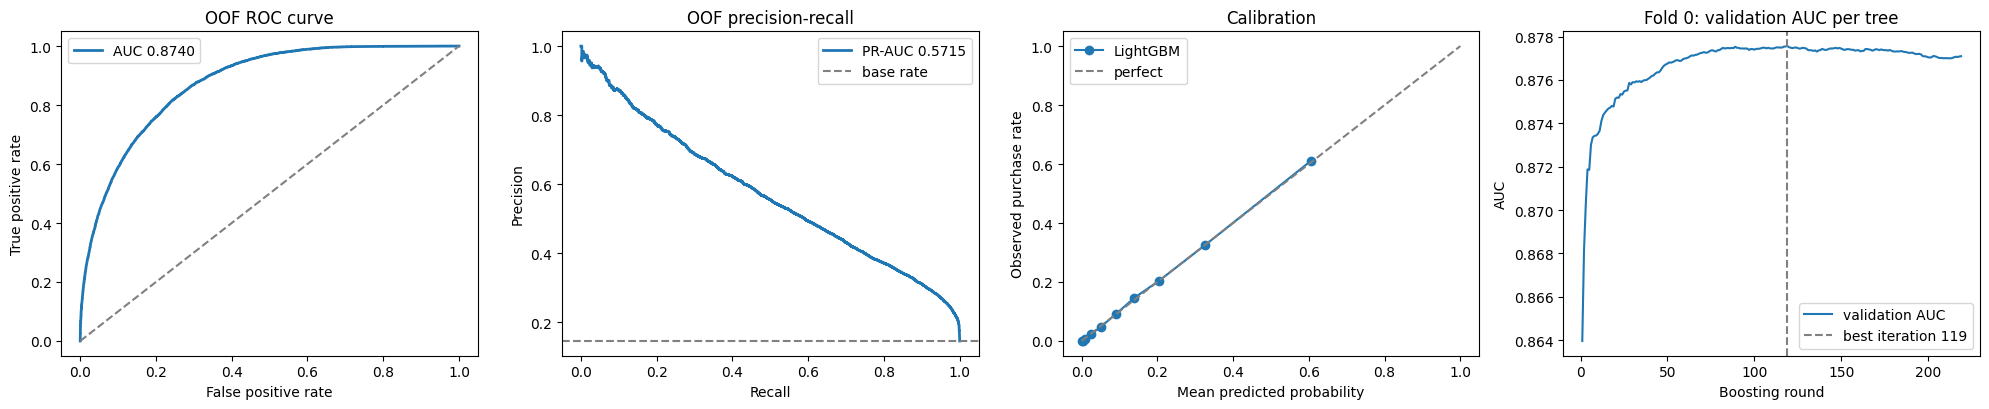

In [12]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))

fpr, tpr, _ = roc_curve(yv, pv)
ax[0].plot(fpr, tpr, lw=2, label=f"AUC {overall['roc_auc']:.4f}"); ax[0].plot([0, 1], [0, 1], "--", c="grey")
ax[0].set(title="OOF ROC curve", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend()

prec, rec_, _ = precision_recall_curve(yv, pv)
ax[1].plot(rec_, prec, lw=2, label=f"PR-AUC {overall['pr_auc']:.4f}"); ax[1].axhline(yv.mean(), ls="--", c="grey", label="base rate")
ax[1].set(title="OOF precision-recall", xlabel="Recall", ylabel="Precision"); ax[1].legend()

frac_pos, mean_pred = calibration_curve(yv, pv, n_bins=10, strategy="quantile")
ax[2].plot(mean_pred, frac_pos, "o-", label="LightGBM"); ax[2].plot([0, 1], [0, 1], "--", c="grey", label="perfect")
ax[2].set(title="Calibration", xlabel="Mean predicted probability", ylabel="Observed purchase rate"); ax[2].legend()

curve = res["curves"][0]
ax[3].plot(range(1, len(curve) + 1), curve, label="validation AUC")
ax[3].axvline(res["models"][0][1], ls="--", c="grey", label=f"best iteration {res['models'][0][1]}")
ax[3].set(title="Fold 0: validation AUC per tree", xlabel="Boosting round", ylabel="AUC"); ax[3].legend()

plt.tight_layout(); plt.savefig("artifacts/lgbm_eval_plots.png", dpi=120); plt.show()

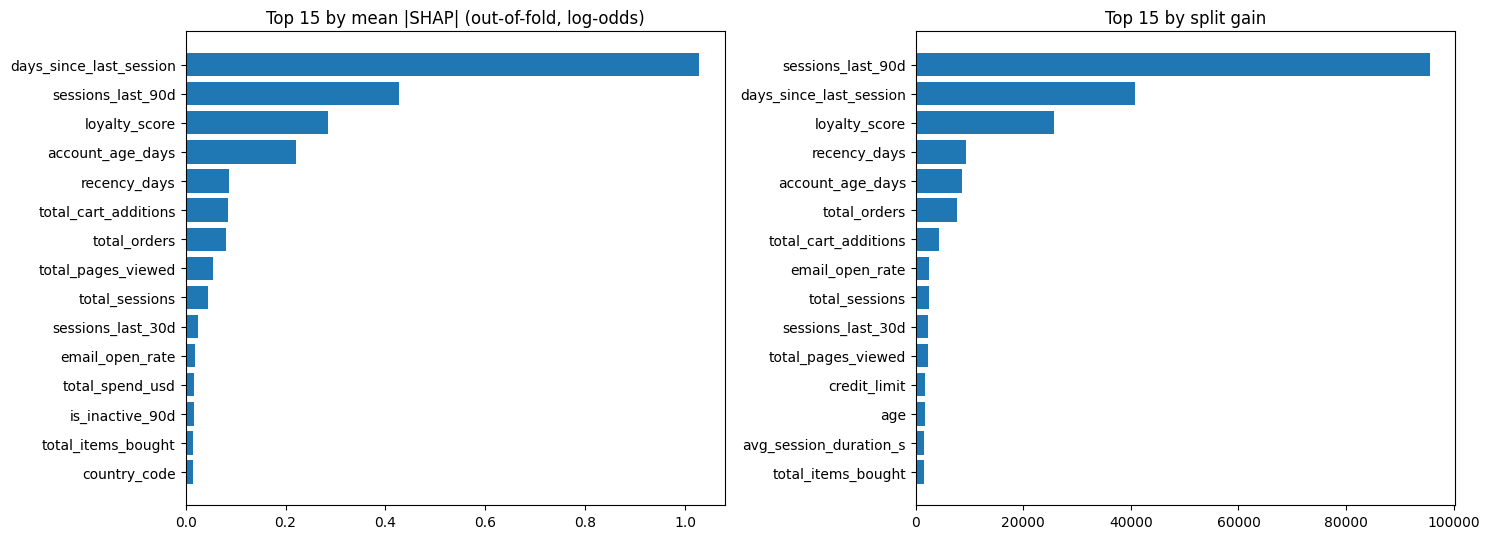

                feature       gain  mean_abs_shap  gain_rank  shap_rank
days_since_last_session 40749.1278         1.0284          2          1
      sessions_last_90d 95511.6131         0.4278          1          2
          loyalty_score 25662.4017         0.2854          3          3
       account_age_days  8682.2187         0.2211          5          4
           recency_days  9383.3686         0.0875          4          5
   total_cart_additions  4322.4991         0.0841          7          6
           total_orders  7687.1221         0.0812          6          7
     total_pages_viewed  2317.6498         0.0547         11          8
         total_sessions  2526.3943         0.0440          9          9
      sessions_last_30d  2326.9121         0.0245         10         10
        email_open_rate  2562.7465         0.0197          8         11
        total_spend_usd  1297.3842         0.0168         17         12


In [13]:
# Out-of-fold SHAP: each fold's model explains a sample of ITS OWN held-out rows.
rng = np.random.RandomState(CONFIG["seed"])
shap_chunks = []
for k, (m, it) in enumerate(res["models"]):
    va_idx = np.where((train_df["fold"] == k).values)[0]
    pick = rng.choice(va_idx, size=min(CONFIG["shap_rows_per_fold"], len(va_idx)), replace=False)
    contrib = m.predict(X.iloc[pick], num_iteration=it, pred_contrib=True)    # [rows, n_features + 1]; last column = baseline
    shap_chunks.append(contrib[:, :-1])
shap_oof = np.vstack(shap_chunks)

imp = pd.DataFrame({
    "feature": FEATURE_COLS,
    "gain": feature_importances,
    "mean_abs_shap": np.abs(shap_oof).mean(axis=0),
})
imp["gain_rank"] = imp["gain"].rank(ascending=False).astype(int)
imp["shap_rank"] = imp["mean_abs_shap"].rank(ascending=False).astype(int)
imp = imp.sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
top = imp.head(15).iloc[::-1]
ax[0].barh(top["feature"], top["mean_abs_shap"]); ax[0].set(title="Top 15 by mean |SHAP| (out-of-fold, log-odds)")
top_g = imp.sort_values("gain", ascending=False).head(15).iloc[::-1]
ax[1].barh(top_g["feature"], top_g["gain"]); ax[1].set(title="Top 15 by split gain")
plt.tight_layout(); plt.savefig("artifacts/lgbm_importance.png", dpi=120); plt.show()

print(imp.head(12).round(4).to_string(index=False))
imp.to_csv("shap_importance_lightgbm.csv", index=False)

# Caution: correlated features (for example sessions_last_30d and sessions_last_90d) share credit, so do not
# over-read single bars. SHAP describes what the MODEL uses, not what causes purchases.

## 8. Why the baseline changed: variant check
This documents the early-stopping diagnosis for the report. The main run above is **pre-declared by CONFIG** (not picked from this table); the table only shows the effect of each design choice.

In [14]:
if CONFIG["run_variants"]:
    variants = {
        "A. original style (AUC+logloss stopping, class-weighted)": make_params(True, metric=["auc", "binary_logloss"]),
        "B. AUC stopping, class-weighted": make_params(True),
    }
    out = []
    for name, prm in variants.items():
        r = run_cv(prm, name)
        e = evaluate_oof(yv, r["oof"])
        out.append(dict(variant=name, mean_best_iter=np.mean([x["best_epoch"] for x in r["rows"]]),
                        roc_auc=e["roc_auc"], pr_auc=e["pr_auc"], brier=e["brier"]))
    out.append(dict(variant=f"MAIN. AUC stopping, class weight={CONFIG['use_class_weight']}",
                    mean_best_iter=np.mean([x["best_epoch"] for x in res["rows"]]),
                    roc_auc=overall["roc_auc"], pr_auc=overall["pr_auc"], brier=overall["brier"]))
    var_df = pd.DataFrame(out)
    print(var_df.round(5).to_string(index=False))
    print("\nRead it like this: variant A stops after very few trees (undertrained); AUC-only stopping trains longer.")
    print("Brier is only comparable between UNWEIGHTED models, because class weights inflate probabilities.")
else:
    print("run_variants is False, skipping.")

                                                 variant  mean_best_iter  roc_auc  pr_auc   brier
A. original style (AUC+logloss stopping, class-weighted)            18.0  0.87165 0.55359 0.10451
                         B. AUC stopping, class-weighted           132.8  0.87340 0.56205 0.14549
                  MAIN. AUC stopping, class weight=False           147.8  0.87400 0.57148 0.08796

Read it like this: variant A stops after very few trees (undertrained); AUC-only stopping trains longer.
Brier is only comparable between UNWEIGHTED models, because class weights inflate probabilities.


## 9. Compare with the FT-Transformer (fold by fold)
Both models use the same folds, so the **paired** per-fold difference is meaningful. Needs `oof_ft_transformer.csv` from the FT-Transformer notebook (upload it next to this notebook).

In [15]:
if os.path.exists(CONFIG["ft_oof_path"]):
    ft = pd.read_csv(CONFIG["ft_oof_path"])[["customer_id", "prob"]].rename(columns={"prob": "ft"})
    cmp_df = train_df[["customer_id", "fold", "target"]].assign(lgbm=oof_preds).merge(ft, on="customer_id", how="left")
    assert cmp_df["ft"].notna().all(), "FT OOF is missing some customers"
    cmp_df["target"] = cmp_df["target"].astype(int)
    rows = []
    for k, g in cmp_df.groupby("fold"):
        rows.append(dict(fold=k, lgbm_roc=roc_auc_score(g.target, g.lgbm), ft_roc=roc_auc_score(g.target, g.ft),
                         lgbm_pr=average_precision_score(g.target, g.lgbm), ft_pr=average_precision_score(g.target, g.ft)))
    c = pd.DataFrame(rows)
    c["d_roc"], c["d_pr"] = c.ft_roc - c.lgbm_roc, c.ft_pr - c.lgbm_pr
    print(c.round(5).to_string(index=False))
    print(f"\nPaired difference FT - LightGBM: ROC-AUC {c.d_roc.mean():+.5f} +/- {c.d_roc.std():.5f} | PR-AUC {c.d_pr.mean():+.5f} +/- {c.d_pr.std():.5f}")
    print("Folds where FT-Transformer is ahead (ROC-AUC):", int((c.d_roc > 0).sum()), "of", len(c))
    for w in (0.3, 0.5, 0.7):
        bl = w * cmp_df.ft + (1 - w) * cmp_df.lgbm
        print(f"blend {w:.1f}*FT + {1-w:.1f}*LGBM | ROC-AUC {roc_auc_score(cmp_df.target, bl):.5f} | PR-AUC {average_precision_score(cmp_df.target, bl):.5f}")
else:
    print(f"'{CONFIG['ft_oof_path']}' not found, skipping.")

 fold  lgbm_roc  ft_roc  lgbm_pr   ft_pr   d_roc    d_pr
    0   0.87757 0.88003  0.58267 0.58558 0.00246 0.00291
    1   0.87148 0.87310  0.56172 0.56280 0.00162 0.00108
    2   0.87583 0.87684  0.57665 0.57927 0.00101 0.00262
    3   0.87486 0.87726  0.57998 0.58509 0.00240 0.00511
    4   0.87069 0.87128  0.56050 0.56302 0.00059 0.00251

Paired difference FT - LightGBM: ROC-AUC +0.00162 +/- 0.00083 | PR-AUC +0.00285 +/- 0.00145
Folds where FT-Transformer is ahead (ROC-AUC): 5 of 5
blend 0.3*FT + 0.7*LGBM | ROC-AUC 0.87494 | PR-AUC 0.57466
blend 0.5*FT + 0.5*LGBM | ROC-AUC 0.87526 | PR-AUC 0.57552
blend 0.7*FT + 0.3*LGBM | ROC-AUC 0.87532 | PR-AUC 0.57543


## 10. Save outputs
| File | Purpose |
|---|---|
| `oof_lightgbm.csv` | `customer_id, prob`: **exactly these two columns**, the format the FT-Transformer notebook's comparison expects |
| `submission_lightgbm_prob.csv` / `_label.csv` | both submission formats (the scoring format is still to be confirmed with the tutor) |
| `shap_importance_lightgbm.csv` | importance table, to compare with the deep model's SHAP later |
| `experiments.jsonl` | one line per run, same schema as the FT-Transformer log |
| `artifacts/lgbm_fold*.txt` | the five fold models (for the agent and for the customer report) |

In [16]:
pd.DataFrame({"customer_id": train_df["customer_id"].values, "prob": oof_preds}).to_csv("oof_lightgbm.csv", index=False)

sub_prob = pd.DataFrame({"customer_id": test_df["customer_id"].astype(int).values, "target": test_preds})
sub_lbl = pd.DataFrame({"customer_id": test_df["customer_id"].astype(int).values, "target": (test_preds >= BEST_THR).astype(int)})
sub_prob.to_csv("submission_lightgbm_prob.csv", index=False)
sub_lbl.to_csv("submission_lightgbm_label.csv", index=False)
print(f"Label file: predicted repurchase rate {sub_lbl['target'].mean():.2%} at threshold {BEST_THR:.2f} (train base rate {y.mean():.2%})")

for k, (m, it) in enumerate(res["models"]):
    m.save_model(f"artifacts/lgbm_fold{k}.txt", num_iteration=it)     # the file also stores the category lists

def log_run(path, record):
    with open(path, "a") as f:
        f.write(json.dumps(record, default=str) + "\n")

log_run("experiments.jsonl", dict(
    run_name=CONFIG["run_name"], model="lightgbm", timestamp=time.strftime("%Y-%m-%d %H:%M"),
    config={k: v for k, v in CONFIG.items() if k != "segment_cuts"},
    params={k: v for k, v in params_main.items()},
    per_fold=res["rows"], overall=overall, lightgbm=lgb.__version__,
    notes="(write what you changed and why here)"))
print("Saved: oof_lightgbm.csv, two submission files, shap_importance_lightgbm.csv, artifacts/lgbm_fold*.txt, experiments.jsonl")

# To keep results after the Colab session ends, download them or copy them to Google Drive:
# from google.colab import files
# for f in ["oof_lightgbm.csv", "folds.csv", "features_v1.parquet", "submission_lightgbm_prob.csv",
#           "submission_lightgbm_label.csv", "shap_importance_lightgbm.csv", "experiments.jsonl"]:
#     files.download(f)

Label file: predicted repurchase rate 18.97% at threshold 0.26 (train base rate 14.57%)
Saved: oof_lightgbm.csv, two submission files, shap_importance_lightgbm.csv, artifacts/lgbm_fold*.txt, experiments.jsonl


## 11. Customer 360 demo with reasons
`test_customer(id)` shows the prediction **and why**. For a **training** customer it uses the fold model that never saw them (a fair, out-of-fold probability); for a **test** customer it averages the five fold models. The segments and actions are an illustrative demo only: the real agent should choose contacts from budget, offer cost and policy.

In [17]:
FOLD_OF = dict(zip(train_df["customer_id"], train_df["fold"]))

def test_customer(customer_id, top_n=5):
    row = df[df["customer_id"] == customer_id]
    if row.empty:
        print(f"Customer {customer_id} not found.")
        return
    Xr = row[FEATURE_COLS]
    if customer_id in FOLD_OF:                       # training customer: use the model that did NOT train on them
        models = [res["models"][FOLD_OF[customer_id]]]
        source = f"out-of-fold (fold {FOLD_OF[customer_id]} model)"
    else:                                            # test customer: average all five fold models
        models = res["models"]
        source = "average of 5 fold models"
    prob = float(np.mean([m.predict(Xr, num_iteration=it)[0] for m, it in models]))
    contrib = np.mean([m.predict(Xr, num_iteration=it, pred_contrib=True)[0][:-1] for m, it in models], axis=0)

    cuts = CONFIG["segment_cuts"]
    if prob >= cuts["organic"]:
        segment, action = "Likely organic buyer", "Probably buys anyway: avoid a discount; save the margin."
    elif prob >= BEST_THR:
        segment, action = "Persuadable lead", "Candidate for a retention offer (subject to policy checks)."
    elif prob >= cuts["at_risk"]:
        segment, action = "At-risk", "Low-cost engagement (email or SMS content)."
    else:
        segment, action = "Dormant", "Review past support tickets; likely suppress from budget."

    r = row.iloc[0]
    notes = []
    if r["do_not_contact"] == 1:
        notes.append("SUPPRESS: customer has opted out of contact.")
    if r["high_priority_open_tickets"] > 0 or r["open_tickets_count"] > 0:
        notes.append("HOLD: open support ticket. Resolve the complaint before any offer.")

    print("=" * 66)
    print(f"CUSTOMER 360: ID {customer_id}  |  probability source: {source}")
    print("=" * 66)
    print(f"Tier: {r['customer_tier']} | Country: {r['country_code']} | Loyalty score: {r['loyalty_score']:.2f}")
    print(f"Spend: ${r['total_spend_usd']:,.2f} over {int(r['total_orders'])} orders | Late deliveries: {int(r['late_deliveries_count'])}")
    print(f"Days since last visit: {r['days_since_last_session']} | Sessions (90d): {int(r['sessions_last_90d'])} | Open tickets: {int(r['open_tickets_count'])}")
    print("-" * 66)
    print(f"Predicted purchase probability (next 30 days): {prob * 100:.1f}%")
    print(f"Segment: {segment}")
    print(f"Suggested action: {action}")
    for n in notes:
        print(f"Policy guard: {n}")
    print("Top reasons (log-odds; + pushes towards buying, - away):")
    for j in np.argsort(-np.abs(contrib))[:top_n]:
        print(f"  {contrib[j]:+.2f}  {FEATURE_COLS[j]} = {r[FEATURE_COLS[j]]}")
    print("=" * 66)

test_customer(CONFIG["demo_customer_id"])

CUSTOMER 360: ID 10126  |  probability source: average of 5 fold models
Tier: Silver | Country: US | Loyalty score: 0.17
Spend: $278.33 over 5 orders | Late deliveries: 0
Days since last visit: 189.0 | Sessions (90d): 0 | Open tickets: 0
------------------------------------------------------------------
Predicted purchase probability (next 30 days): 1.5%
Segment: Dormant
Suggested action: Review past support tickets; likely suppress from budget.
Top reasons (log-odds; + pushes towards buying, - away):
  -0.91  days_since_last_session = 189.0
  -0.47  sessions_last_90d = 0
  +0.17  recency_days = 189.0
  -0.13  loyalty_score = 0.175
  -0.12  account_age_days = 777.0


## 12. Code review cheat sheet
**Say it in one breath:** *"We aggregate each customer's history to the 30 Sep cutoff in SQL, train 5 LightGBM models on the shared folds with AUC-based early stopping, predict each held-out fold to get honest out-of-fold probabilities, and average the five models for the test set. We evaluate ranking (ROC/PR-AUC, precision@k) and calibration, and explain predictions with SHAP computed on held-out rows."*

| Piece | What it does | What breaks if removed or changed |
|---|---|---|
| Shared `folds.csv` | identical splits across models | scores are not comparable between models |
| `'Delivered Late'` filter plus the assertion | feature matches the real status spelling | feature silently becomes 0 again |
| `metric='auc'` only | early stopping tracks the ranking metric | logloss-triggered stop undertrains the model (see section 8) |
| `bagging_freq=1` | makes `bagging_fraction` actually apply | row subsampling silently disabled |
| `use_class_weight=False` | plain loss, calibrated probabilities | with weights, probabilities are inflated and budget maths is wrong |
| OOF predictions | every customer is scored by a model that never saw them | training-set scores are meaninglessly high |
| Test = mean of 5 fold models | uses all the data, reduces variance | a single fold model sees only 80% of the data |
| `pred_contrib=True` | built-in SHAP in log-odds | no explanation for W2 |
| `oof_lightgbm.csv` has only `customer_id, prob` | format the comparison cell expects | an extra `fold` column would break the merge |

**Likely questions**
- *Why was the old baseline wrong?* Three things: the late feature was always 0; early stopping on logloss under class weights stopped after ~18 trees; subsampling was a no-op.
- *Why no class weights?* AUC is nearly unaffected, and probabilities stay calibrated for the agent's expected-value decisions.
- *What would you not trust in production?* Calibration on future months (one snapshot), the demo segment cut-offs, and SHAP on correlated features.

**AI Use Log reminder:** log what you asked, what you accepted or changed, and **what you checked** (the late-delivery assertion, the identical-folds check, the variant table, the OOF file format).